In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

DATASET_NAME = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"

dataset = load_dataset(DATASET_NAME, split="train")
df = dataset.to_pandas()

df.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


### Basic Dataset Information

In [3]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Rows: 26872
Columns: 5

Columns:
['flags', 'instruction', 'category', 'intent', 'response']

Missing values:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Duplicate rows:
0


### Inspecting the 11 Categories

In [4]:
categories = sorted(df["category"].unique())

print(f"Number of categories: {len(categories)}")

for category in categories:
  print(category)

Number of categories: 11
ACCOUNT
CANCEL
CONTACT
DELIVERY
FEEDBACK
INVOICE
ORDER
PAYMENT
REFUND
SHIPPING
SUBSCRIPTION


### Inspecting all the 27 intents

In [5]:
intents = sorted(df['intent'].unique())

print(f"Number of intents: {len(intents)}")

for intent in intents:
  print(intent)

Number of intents: 27
cancel_order
change_order
change_shipping_address
check_cancellation_fee
check_invoice
check_payment_methods
check_refund_policy
complaint
contact_customer_service
contact_human_agent
create_account
delete_account
delivery_options
delivery_period
edit_account
get_invoice
get_refund
newsletter_subscription
payment_issue
place_order
recover_password
registration_problems
review
set_up_shipping_address
switch_account
track_order
track_refund


### Category Distribution

In [6]:
category_counts = df['category'].value_counts()

category_counts

category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

<small>Calculate percentage of category distribution

In [7]:
category_distribution = pd.DataFrame({
  "count": category_counts,
  "percentage": (category_counts / len(df) * 100).round(2)
})

category_distribution

,count,percentage
category,,
ACCOUNT,5986,22.28
ORDER,3988,14.84
REFUND,2992,11.13
INVOICE,1999,7.44
CONTACT,1999,7.44
PAYMENT,1998,7.44
FEEDBACK,1997,7.43
DELIVERY,1994,7.42
SHIPPING,1970,7.33


### Intent Distribution

In [8]:
intent_counts = df['intent'].value_counts()

intent_distribution = pd.DataFrame({
  "count": intent_counts,
  "percentage": (intent_counts / len(df) * 100).round(2)
})

intent_distribution

,count,percentage
intent,,
check_invoice,1000,3.72
complaint,1000,3.72
contact_customer_service,1000,3.72
edit_account,1000,3.72
switch_account,1000,3.72
check_payment_methods,999,3.72
contact_human_agent,999,3.72
delivery_period,999,3.72
get_invoice,999,3.72


### Verifying which category each intent belongs to

In [9]:
intent_category_mapping = (
  df[["intent", "category"]]
  .drop_duplicates()
  .sort_values(["category","intent"])
)

intent_category_mapping

,intent,category
9913,create_account,ACCOUNT
10910,delete_account,ACCOUNT
13899,edit_account,ACCOUNT
19891,recover_password,ACCOUNT
20886,registration_problems,ACCOUNT
23879,switch_account,ACCOUNT
2968,check_cancellation_fee,CANCEL
7914,contact_customer_service,CONTACT
8914,contact_human_agent,CONTACT
11905,delivery_options,DELIVERY


In [10]:
intent_category_counts = (
  df.groupby("intent")["category"]
  .nunique()
  .sort_values(ascending=False)
)

intent_category_counts

intent
cancel_order                1
change_order                1
change_shipping_address     1
check_cancellation_fee      1
check_invoice               1
check_payment_methods       1
check_refund_policy         1
complaint                   1
contact_customer_service    1
contact_human_agent         1
create_account              1
delete_account              1
delivery_options            1
delivery_period             1
edit_account                1
get_invoice                 1
get_refund                  1
newsletter_subscription     1
payment_issue               1
place_order                 1
recover_password            1
registration_problems       1
review                      1
set_up_shipping_address     1
switch_account              1
track_order                 1
track_refund                1
Name: category, dtype: int64

### Check if any intent belongs to more than 1 category

In [11]:
inconsistent_intents = intent_category_counts[
    intent_category_counts > 1
]

if len(inconsistent_intents) == 0:
    print("All intents map to exactly one category.")
else:
    print("Warning: Some intents map to multiple categories.")
    print(inconsistent_intents)

All intents map to exactly one category.


### Visualize category vs tickets

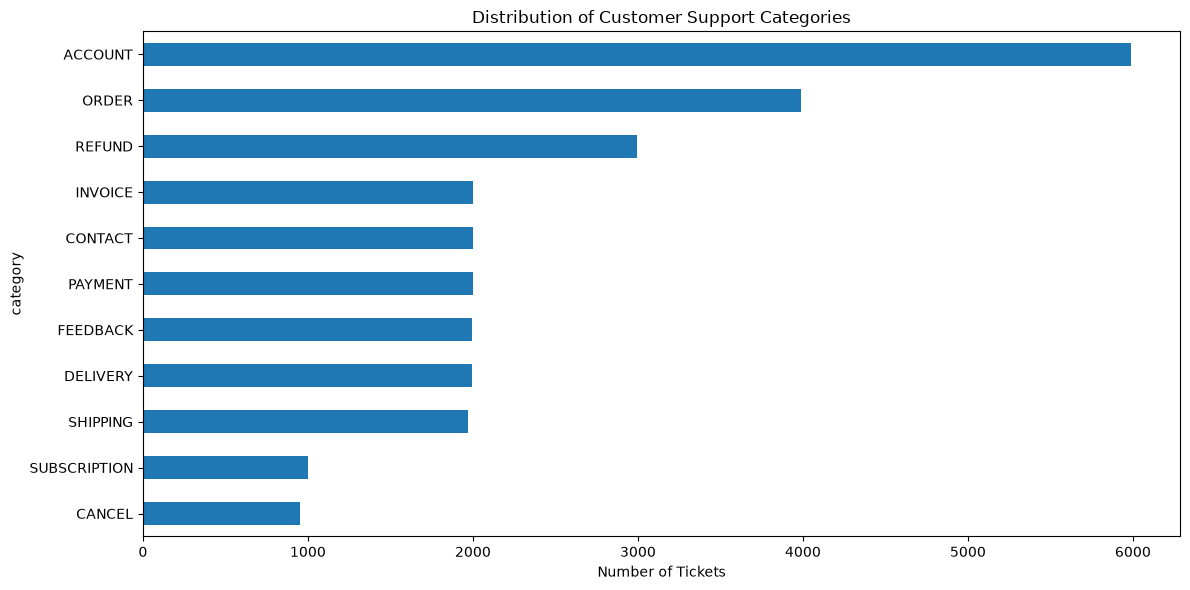

In [12]:
plt.figure(figsize=(12,6))

category_counts.sort_values().plot(kind='barh')

plt.title("Distribution of Customer Support Categories")
plt.xlabel("Number of Tickets")
plt.ylabel("category")

plt.tight_layout()
plt.show()

### Visualizing Intent vs ticket count

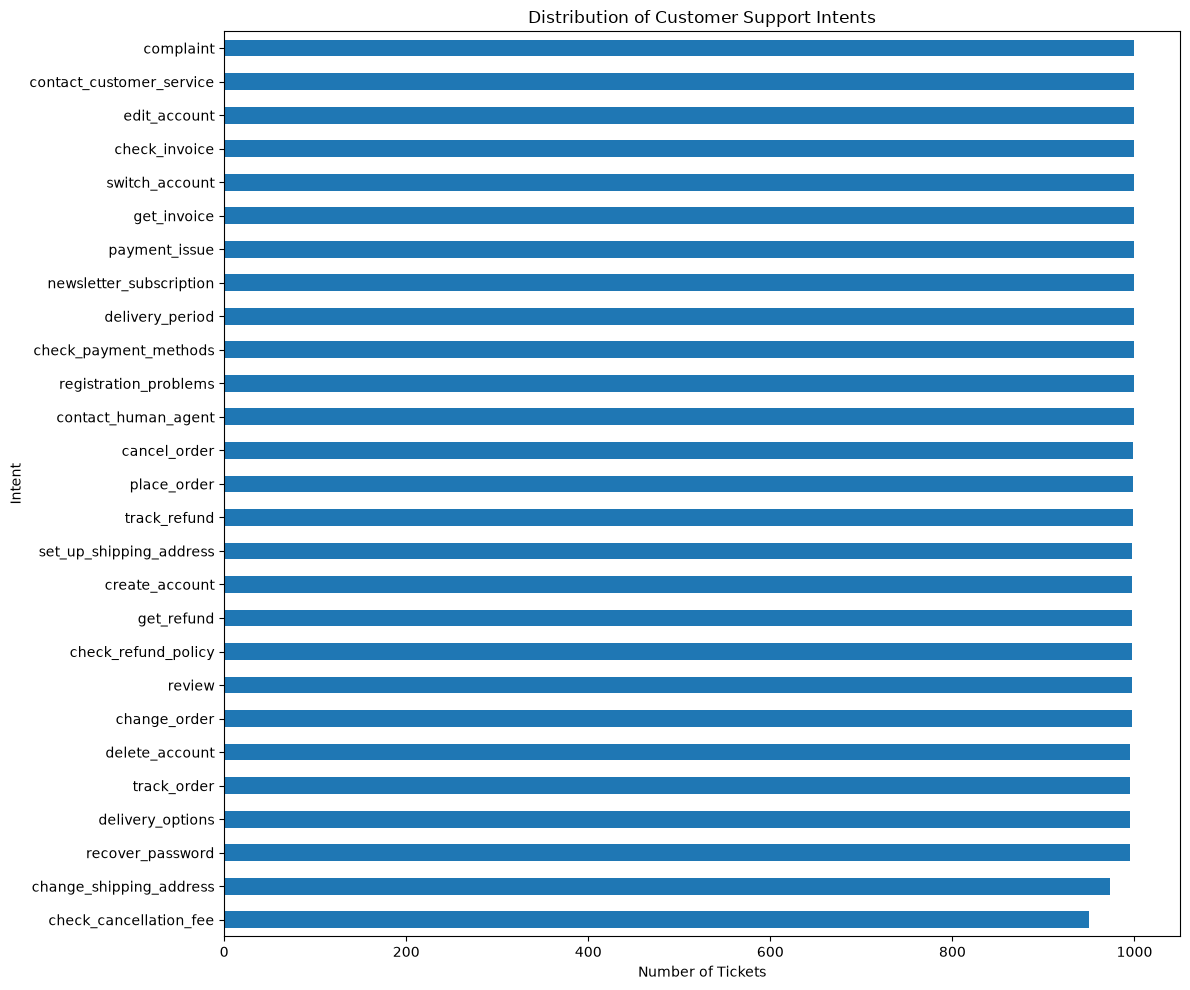

In [13]:
plt.figure(figsize=(12, 10))

intent_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Customer Support Intents")
plt.xlabel("Number of Tickets")
plt.ylabel("Intent")

plt.tight_layout()
plt.show()

## Priliminnary EDA Conclusions


Initial dataset analysis identified 26,872 complete records with no exact duplicates or missing values. The 27 intent classes are highly balanced, containing approximately 950–1,000 samples each. However, the 11 parent categories are imbalanced, ranging from 950 to 5,986 samples. Further analysis showed that this imbalance is primarily structural: categories contain different numbers of constituent intents, while individual intents remain approximately equally represented. All 27 intents map uniquely to a single parent category, indicating consistent hierarchical labeling.

## Moving on with more objectives

<small>

1. Are there duplicate instructions, even though there are no duplicate full rows?

2. Does the same instruction ever have conflicting labels?

3. How long are customer messages?

4. What placeholders such as ```{{Order Number}}``` occur?

5. Could those placeholders accidentally make classification too easy?

6. What is the ```flags``` column, and should we use it?

7. Are there normalized/near-duplicate messages?


#### Check Duplicate Customer Instructions

<small> A row can be unique because the ```response``` differes even when the customer question is identical

In [14]:
duplicate_instructions = df['instruction'].duplicated().sum()

print(f"Duplicate instructions: {duplicate_instructions}")

print(
  f"Percentage: "
  f"{duplicate_instructions / len(df) * 100:.2f}%"
)

Duplicate instructions: 2237
Percentage: 8.32%


In [15]:
df[
    df["instruction"].duplicated(keep=False)
].sort_values("instruction").head(20)

,flags,instruction,category,intent,response
25320,BK,ETA of order {{Order Number}},ORDER,track_order,It's great to hear from you! I can see that yo...
25447,BK,ETA of order {{Order Number}},ORDER,track_order,We're all ears! I'm tuned into the idea that y...
25557,BK,ETA of order {{Order Number}},ORDER,track_order,Thank you for your query! I understand that yo...
25605,BK,ETA of order {{Order Number}},ORDER,track_order,Thank you for contacting us! I'm here to assis...
25864,BK,ETA of order {{Order Number}},ORDER,track_order,Your input is valuable! I'm picking up that yo...
24880,BKLQ,ETA of purchase {{Order Number}},ORDER,track_order,Thank you for reaching out! I'm here to assist...
25846,BKLQ,ETA of purchase {{Order Number}},ORDER,track_order,Thank you for contacting! I certainly recogniz...
235,B,I am trying to cancel order {{Order Number}},ORDER,cancel_order,I've been informed that you're currently attem...
636,B,I am trying to cancel order {{Order Number}},ORDER,cancel_order,I've realized that you are trying to cancel yo...
418,BLZ,I am trying to cancel purchaes {{Order Number}},ORDER,cancel_order,I hear you loud and clear that you're trying t...


#### Check whether identical instructions have conflicting intents

In [16]:
instruction_intent_counts = (
  df.groupby("instruction")["intent"]
  .nunique()
)

conflicting_instructions = instruction_intent_counts[
  instruction_intent_counts > 1
]

print(
  f"Instruction mapped to multiple intents: "
  f"{len(conflicting_instructions)}"
)

Instruction mapped to multiple intents: 0


In [17]:
if len(conflicting_instructions) > 0:
    example_text = conflicting_instructions.index[0]

    display(
        df[df["instruction"] == example_text][
            ["instruction", "category", "intent"]
        ]
    )

#### Analyze customer-message lengths

In [18]:
df["instruction_char_length"] = (
  df["instruction"].str.len()
)
df["instruction_word_count"] = (
  df['instruction'].str.split().str.len()
)

In [19]:
df[
  ["instruction_char_length", "instruction_word_count"]
].describe()

,instruction_char_length,instruction_word_count
count,26872.000000,26872.000000
mean,46.889513,8.690979
std,10.897578,2.605004
min,6.000000,1.000000
25%,40.000000,7.000000
50%,48.000000,9.000000
75%,55.000000,11.000000
max,92.000000,16.000000


Visualize word counts

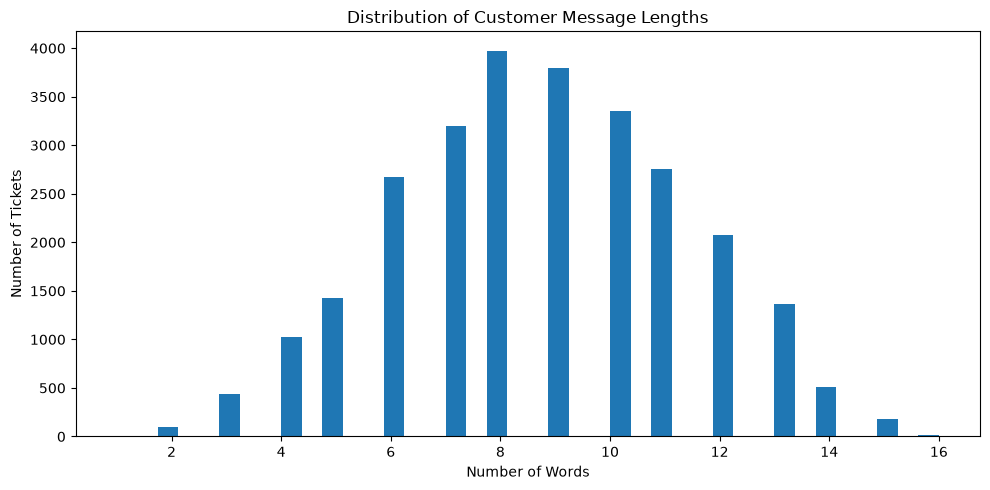

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
  df['instruction_word_count'],
  bins=40
)

plt.title("Distribution of Customer Message Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

Inspecting unusually short messages

In [21]:
df.nsmallest(
  10,
  "instruction_word_count"
)[
  ["instruction", "category", "intent", "instruction_word_count"]
]

,instruction,category,intent,instruction_word_count
7449,complaint,FEEDBACK,complaint,1
9025,contactingassistant,CONTACT,contact_human_agent,1
10231,register,ACCOUNT,create_account,1
19665,makepurchase,ORDER,place_order,1
22443,review,FEEDBACK,review,1
83,cancelling order,ORDER,cancel_order,2
311,canceling order,ORDER,cancel_order,2
370,cancel purchase732201349959,ORDER,cancel_order,2
711,order cancelation,ORDER,cancel_order,2
729,cancel purchase370795561790,ORDER,cancel_order,2


Inspection unusually long ones

In [22]:
df.nlargest(
    10,
    "instruction_word_count"
)[
    ["instruction", "category", "intent", "instruction_word_count"]
]

,instruction,category,intent,instruction_word_count
9942,I do not know what to do to create a {{Account...,ACCOUNT,create_account,16
9951,I want to open a {{Account Type}} account for ...,ACCOUNT,create_account,16
10969,I do not know what I have to do to remove a da...,ACCOUNT,delete_account,16
13603,i have to see how soon can i expect my item oh...,DELIVERY,delivery_period,16
16526,i have paid {{Currency Symbol}}{{Refund Amount...,REFUND,get_refund,16
16545,i do not know what i have to do to ask for a r...,REFUND,get_refund,16
19503,I do not know what I need to do to buy a few o...,ORDER,place_order,16
19541,I do not nkow what I have to do to order a few...,ORDER,place_order,16
24131,i do not know what i need to do to switch to t...,ACCOUNT,switch_account,16
24184,i do not know what i have to do to change to t...,ACCOUNT,switch_account,16


#### Investigating Placeholders

In [23]:
import re

def extract_placeholdeers(text):
  return re.findall(r"\{\{.*?\}\}", text)

df['placeholders'] = df['instruction'].apply(
  extract_placeholdeers
)

In [24]:
placeholder_counts = (
  df['placeholders']
  .explode()
  .dropna()
  .value_counts()
)
placeholder_counts

placeholders
{{Order Number}}        2907
{{Account Type}}        1011
{{Person Name}}          887
{{Account Category}}     822
{{Refund Amount}}        624
{{Currency Symbol}}      372
{{Delivery City}}        234
{{Delivery Country}}     177
{{Invoice Number}}         8
Name: count, dtype: int64

In [25]:
rows_with_placeholders = (
    df["placeholders"].apply(len) > 0
).sum()

print(f"Rows containing placeholders: {rows_with_placeholders}")

print(
    f"Percentage: "
    f"{rows_with_placeholders / len(df) * 100:.2f}%"
)

Rows containing placeholders: 6670
Percentage: 24.82%


#### Check Place holder Intent Relationships

In [26]:
placeholder_rows = df.explode(
    "placeholders",
    ignore_index=True
)

placeholder_rows = placeholder_rows[
    placeholder_rows["placeholders"].notna()
]

placeholder_intent_table = pd.crosstab(
    placeholder_rows["placeholders"],
    placeholder_rows["intent"]
)

placeholder_intent_table

intent,cancel_order,change_order,check_invoice,create_account,delete_account,delivery_options,edit_account,get_invoice,get_refund,switch_account,track_order,track_refund
placeholders,,,,,,,,,,,,
{{Account Category}},0,0,0,217,204,0,183,0,0,218,0,0
{{Account Type}},0,0,0,267,286,0,190,0,0,268,0,0
{{Currency Symbol}},0,0,0,0,0,0,0,0,143,0,0,229
{{Delivery City}},0,0,0,0,0,234,0,0,0,0,0,0
{{Delivery Country}},0,0,0,0,0,177,0,0,0,0,0,0
{{Invoice Number}},0,0,3,0,0,0,0,5,0,0,0,0
{{Order Number}},973,965,0,0,0,0,0,0,0,0,969,0
{{Person Name}},0,0,438,0,0,0,0,449,0,0,0,0
{{Refund Amount}},0,0,0,0,0,0,0,0,196,0,0,428


In [27]:
placeholder_mapping = (
    placeholder_rows
    .groupby("placeholders")["intent"]
    .nunique()
    .sort_values()
)

placeholder_mapping

placeholders
{{Delivery City}}       1
{{Delivery Country}}    1
{{Invoice Number}}      2
{{Currency Symbol}}     2
{{Person Name}}         2
{{Refund Amount}}       2
{{Order Number}}        3
{{Account Category}}    4
{{Account Type}}        4
Name: intent, dtype: int64

In [28]:
placeholder_intent_counts = (
    placeholder_rows
    .groupby(["placeholders", "intent"])
    .size()
    .reset_index(name="count")
    .sort_values(["placeholders", "count"], ascending=[True, False])
)

placeholder_intent_counts

,placeholders,intent,count
3,{{Account Category}},switch_account,218
0,{{Account Category}},create_account,217
1,{{Account Category}},delete_account,204
2,{{Account Category}},edit_account,183
5,{{Account Type}},delete_account,286
7,{{Account Type}},switch_account,268
4,{{Account Type}},create_account,267
6,{{Account Type}},edit_account,190
9,{{Currency Symbol}},track_refund,229
8,{{Currency Symbol}},get_refund,143


In [29]:
placeholder_intent_counts["percentage"] = (
    placeholder_intent_counts["count"]
    / placeholder_intent_counts
        .groupby("placeholders")["count"]
        .transform("sum")
    * 100
).round(2)

placeholder_intent_counts

,placeholders,intent,count,percentage
3,{{Account Category}},switch_account,218,26.52
0,{{Account Category}},create_account,217,26.40
1,{{Account Category}},delete_account,204,24.82
2,{{Account Category}},edit_account,183,22.26
5,{{Account Type}},delete_account,286,28.29
7,{{Account Type}},switch_account,268,26.51
4,{{Account Type}},create_account,267,26.41
6,{{Account Type}},edit_account,190,18.79
9,{{Currency Symbol}},track_refund,229,61.56
8,{{Currency Symbol}},get_refund,143,38.44


#### Inspect the mysterious ```flags``` column

In [30]:
print(f"Unique flags: {df['flags'].nunique()}")

df["flags"].value_counts().head(20)

Unique flags: 394


flags
BL       5212
BLQ      2467
BIL      2138
BLM      1297
BILQ     1057
BLQZ      970
BLZ       902
BKL       862
BLMQ      600
BEL       533
BILM      521
BCL       484
BCIL      427
BILQZ     412
BILP      363
B         353
BK        352
BQ        340
BKLZ      322
BLW       309
Name: count, dtype: int64

In [31]:
df[
    ["flags", "instruction", "intent"]
].head(20)

,flags,instruction,intent
0,B,question about cancelling order {{Order Number}},cancel_order
1,BQZ,i have a question about cancelling oorder {{Or...,cancel_order
2,BLQZ,i need help cancelling puchase {{Order Number}},cancel_order
3,BL,I need to cancel purchase {{Order Number}},cancel_order
4,BCELN,"I cannot afford this order, cancel purchase {{...",cancel_order
5,BI,can you help me cancel order {{Order Number}}?,cancel_order
6,BCLN,"I can no longer afford order {{Order Number}},...",cancel_order
7,BL,I am trying to cancel purchase {{Order Number}},cancel_order
8,BL,I have got to cancel purchase {{Order Number}},cancel_order
9,BLQ,i need help canceling purchase {{Order Number}},cancel_order


#### Look for normalized duplicates

In [32]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)

    return text


df["normalized_instruction"] = (
    df["instruction"].apply(normalize_text)
)

In [33]:
normalized_duplicates = (
    df["normalized_instruction"]
    .duplicated()
    .sum()
)

print(
    f"Normalized duplicate instructions: "
    f"{normalized_duplicates}"
)

Normalized duplicate instructions: 2598


In [34]:
normalized_conflicts = (
    df.groupby("normalized_instruction")["intent"]
    .nunique()
)

normalized_conflicts = normalized_conflicts[
    normalized_conflicts > 1
]

print(
    f"Normalized texts with conflicting intents: "
    f"{len(normalized_conflicts)}"
)

Normalized texts with conflicting intents: 0


### Split combined flags into individual tags

In [36]:
flag_rows = (
  df.assign(flag=df['flags'].apply(list))
  .explode("flag", ignore_index=True)
)

flag_rows[
  ['flags','flag','instruction','intent']
].head(20)

,flags,flag,instruction,intent
0,B,B,question about cancelling order {{Order Number}},cancel_order
1,BQZ,B,i have a question about cancelling oorder {{Or...,cancel_order
2,BQZ,Q,i have a question about cancelling oorder {{Or...,cancel_order
3,BQZ,Z,i have a question about cancelling oorder {{Or...,cancel_order
4,BLQZ,B,i need help cancelling puchase {{Order Number}},cancel_order
5,BLQZ,L,i need help cancelling puchase {{Order Number}},cancel_order
6,BLQZ,Q,i need help cancelling puchase {{Order Number}},cancel_order
7,BLQZ,Z,i need help cancelling puchase {{Order Number}},cancel_order
8,BL,B,I need to cancel purchase {{Order Number}},cancel_order
9,BL,L,I need to cancel purchase {{Order Number}},cancel_order


### Count Individual flags

In [37]:
individual_flag_counts = (
  flag_rows["flag"]
  .value_counts()
)
individual_flag_counts

flag
B    26872
L    24115
Q     8968
I     7839
Z     5286
M     4920
C     2646
K     2227
E     1882
P     1329
W     1288
N      463
S      417
V       77
Name: count, dtype: int64

In [38]:
# Counting how much of the dataset contains each flag

individual_flag_distribution = pd.DataFrame({
  "count": individual_flag_counts,
  "percentage_of_rows": (
    individual_flag_counts/len(df) * 100
  ).round(2)
})

individual_flag_distribution

,count,percentage_of_rows
flag,,
B,26872,100.00
L,24115,89.74
Q,8968,33.37
I,7839,29.17
Z,5286,19.67
M,4920,18.31
C,2646,9.85
K,2227,8.29
E,1882,7.00


### Check which intents each flag occurs in

In [39]:
flag_intent_mapping = (
  flag_rows
  .groupby("flag")["intent"]
  .nunique()
  .sort_values()
)

flag_intent_mapping

flag
S     1
V     4
N     9
M    19
I    27
E    27
B    27
C    27
K    27
L    27
Q    27
P    27
W    27
Z    27
Name: intent, dtype: int64

#### Lets look at robustness releated flags

In [42]:
interesting_flags = ["Z", "Q", "N", "K", "P"]

for flag in interesting_flags:
    print(f"\n===== FLAG: {flag} =====")

    display(
        df[
            df["flags"].str.contains(flag)
        ][
            ["flags", "instruction", "intent"]
        ].head(8)
    )


===== FLAG: Z =====


,flags,instruction,intent
1,BQZ,i have a question about cancelling oorder {{Or...,cancel_order
2,BLQZ,i need help cancelling puchase {{Order Number}},cancel_order
14,BLZ,help me canceling purchase {{Order Number}},cancel_order
22,BLZ,assistance with cancelling pucrhase {{Order Nu...,cancel_order
24,BZ,help cnceling order {{Order Number}},cancel_order
28,BZ,assistnace cancelling order {{Order Number}},cancel_order
31,BLZ,assistance with cancelling pucrhase {{Order Nu...,cancel_order
32,BQZ,want assistance to cancel order {{Order Number}},cancel_order



===== FLAG: Q =====


,flags,instruction,intent
1,BQZ,i have a question about cancelling oorder {{Or...,cancel_order
2,BLQZ,i need help cancelling puchase {{Order Number}},cancel_order
9,BLQ,i need help canceling purchase {{Order Number}},cancel_order
10,BQ,i dont know what to do to cancel order {{Order...,cancel_order
18,BQ,need help with canceling order {{Order Number}},cancel_order
19,BQ,i want assistance canceling order {{Order Numb...,cancel_order
20,BQ,I'm trying to cancel order {{Order Number}},cancel_order
21,BMQ,i have problems with canceling order {{Order N...,cancel_order



===== FLAG: N =====


,flags,instruction,intent
4,BCELN,"I cannot afford this order, cancel purchase {{...",cancel_order
6,BCLN,"I can no longer afford order {{Order Number}},...",cancel_order
36,BLN,I can no longer afford purchase {{Order Number}},cancel_order
39,BCELNQZ,i do not want these article i try to cancel or...,cancel_order
54,BLN,I can't afford purchase {{Order Number}},cancel_order
58,BCLN,"I can't afford order {{Order Number}}, help me...",cancel_order
62,BCELNV,I cannot pay for the last purchase I have made...,cancel_order
73,BCILN,"I can't pay for this item, can I cancel order ...",cancel_order



===== FLAG: K =====


,flags,instruction,intent
50,BK,canceling order {{Order Number}},cancel_order
83,BK,cancelling order,cancel_order
142,BKL,cancel purchase {{Order Number}},cancel_order
155,BKL,cancel purchase {{Order Number}},cancel_order
157,BKL,cancel purchase {{Order Number}},cancel_order
168,BKL,canceling purchase {{Order Number}},cancel_order
191,BKZ,canmcel order {{Order Number}},cancel_order
200,BKZ,camceling order {{Order Number}},cancel_order



===== FLAG: P =====


,flags,instruction,intent
38,BLP,I would like to cancel purchase {{Order Number}},cancel_order
45,BIPQ,could ya help me cancel order {{Order Number}},cancel_order
46,BIPZ,could you help me cancelling order {{Order Num...,cancel_order
64,BILP,could you help me cancel purchase {{Order Numb...,cancel_order
75,BILP,where could I cancel purchase {{Order Number}}?,cancel_order
105,BCLP,I would like to cancel purchase {{Order Number...,cancel_order
113,BILPQ,would it be possible to cancel purchase {{Orde...,cancel_order
114,BILP,could you help me canceling purchase {{Order N...,cancel_order


### Compare Each flag across intents

In [43]:
flag_intent_counts = (
  flag_rows
  .groupby(["flag", "intent"])
  .size()
  .reset_index(name="count")
)

flag_intent_counts

,flag,intent,count
0,B,cancel_order,998
1,B,change_order,997
2,B,change_shipping_address,973
3,B,check_cancellation_fee,950
4,B,check_invoice,1000
...,...,...,...
298,Z,review,197
299,Z,set_up_shipping_address,199
300,Z,switch_account,189
301,Z,track_order,187


In [44]:
flag_intent_counts[
    flag_intent_counts["flag"] == "Z"
].sort_values("count", ascending=False)

,flag,intent,count
284,Z,contact_customer_service,200
285,Z,contact_human_agent,200
281,Z,check_payment_methods,200
283,Z,complaint,200
296,Z,recover_password,200
299,Z,set_up_shipping_address,199
282,Z,check_refund_policy,199
288,Z,delivery_options,199
289,Z,delivery_period,199
287,Z,delete_account,199


In [45]:
flag_intent_counts[
    flag_intent_counts["flag"] == "Q"
].sort_values("count", ascending=False)

,flag,intent,count
239,Q,review,418
237,Q,recover_password,395
242,Q,track_order,389
235,Q,payment_issue,385
233,Q,get_refund,368
232,Q,get_invoice,364
223,Q,check_refund_policy,355
243,Q,track_refund,353
224,Q,complaint,352
238,Q,registration_problems,347


In [46]:
flag_intent_counts[
    flag_intent_counts["flag"] == "N"
].sort_values("count", ascending=False)

,flag,intent,count
181,N,cancel_order,133
186,N,registration_problems,107
182,N,change_order,64
188,N,track_order,38
185,N,recover_password,37
184,N,create_account,34
189,N,track_refund,33
187,N,switch_account,11
183,N,check_invoice,6


### Quantiy how evenly each flag is distributed

In [47]:
flag_intent_summary = (
    flag_rows
    .groupby("flag")
    .agg(
        total_occurrences=("intent", "size"),
        unique_intents=("intent", "nunique")
    )
    .sort_values("unique_intents")
)

flag_intent_summary

,total_occurrences,unique_intents
flag,,
S,417,1
V,77,4
N,463,9
M,4920,19
I,7839,27
E,1882,27
B,26872,27
C,2646,27
K,2227,27


## EDA Conclusions

1. The dataset contains 26,872 rows and 5 original columns:
   `flags`, `instruction`, `category`, `intent`, and `response`.

2. There are no missing values and no exact duplicate rows.

3. The dataset contains 27 intents and 11 categories. The intent classes are
   highly balanced, with roughly 950–1,000 samples per intent.

4. Every intent maps to exactly one category, showing consistent hierarchical
   labeling between intent and category.

5. Category distribution is imbalanced because different categories contain
   different numbers of intents. For example, ACCOUNT contains multiple intents
   while categories such as CANCEL and SUBSCRIPTION contain only one.

6. There are 2,237 duplicate instruction occurrences (8.32% of the dataset).
   After lowercasing and whitespace normalization, there are 2,598 normalized
   duplicate instruction occurrences. None of these normalized duplicate texts
   map to conflicting intents.

7. Customer messages are short. The average instruction length is about
   8.69 words, with examples ranging from 1 word to 16 words. Therefore,
   the problem is primarily short-text classification.

8. There are 9 distinct placeholder types. 6,670 rows (24.82% of the dataset)
   contain at least one placeholder.

9. Some placeholders are strongly associated with only one or a few intents.
   This creates a shortcut-learning risk, where the model may learn synthetic
   placeholder patterns instead of understanding the actual meaning of the
   customer's query.

10. The `flags` column should not be used as a model input because it is
    dataset-generation metadata that would not exist in real production queries.
    However, it can be useful for robustness evaluation.

11. Flags such as `Z`, `Q`, `K`, and `P` are useful robustness slices because
    they appear across all 27 intents. They can later help evaluate performance
    on typo-heavy, colloquial, keyword-style, and polite queries.

12. The `N` flag can also be used for supplementary analysis, but it covers
    only 9 intents, so its performance should not be treated as a general
    robustness score.

13. Because duplicate and normalized-equivalent instructions exist, the
    train/validation/test split must prevent equivalent instructions from
    appearing in more than one split. Otherwise, evaluation scores could be
    artificially inflated by data leakage.